In [ ]:
# Real Estate Housing Price Prediction

## Datheon AI/ML Internship – Task 2

### Objective
To develop and compare machine learning regression models
for predicting median housing prices using the California
housing dataset.

### Models
- Ordinary Least Squares (Linear Regression)
- Ridge Regression (L2 Regularization)
- Lasso Regression (L1 Regularization)

### Evaluation Metrics
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R² Score

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge, Lasso

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (20640, 10)

First 5 Rows:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB

Statistical Summary:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [4]:
print("Missing Values:")

missing_values = df.isnull().sum()

display(
    missing_values[missing_values > 0]
)

Missing Values:


total_bedrooms    207
dtype: int64

In [5]:
# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check data types
print("\nData types:")
print(df.dtypes)

# Check unique values in categorical column
print("\nOcean proximity categories:")
print(df["ocean_proximity"].value_counts())

Duplicate rows: 0

Missing values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Data types:
longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity           str
dtype: object

Ocean proximity categories:
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


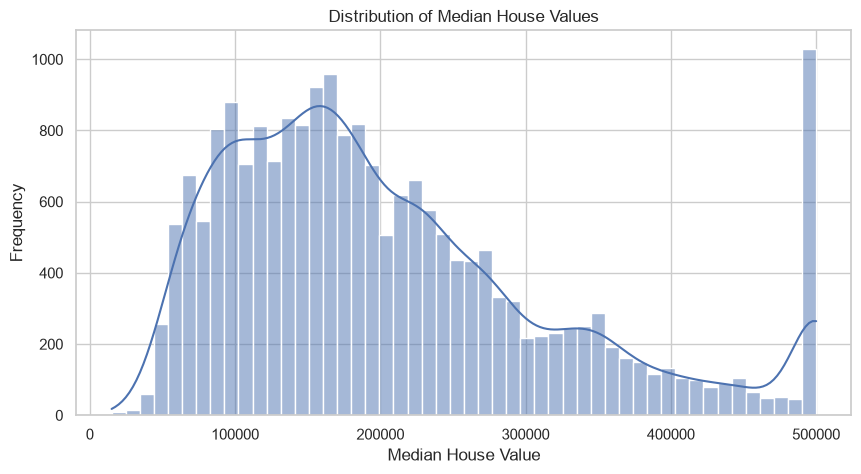

In [6]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["median_house_value"],
    bins=50,
    kde=True
)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")

plt.show()

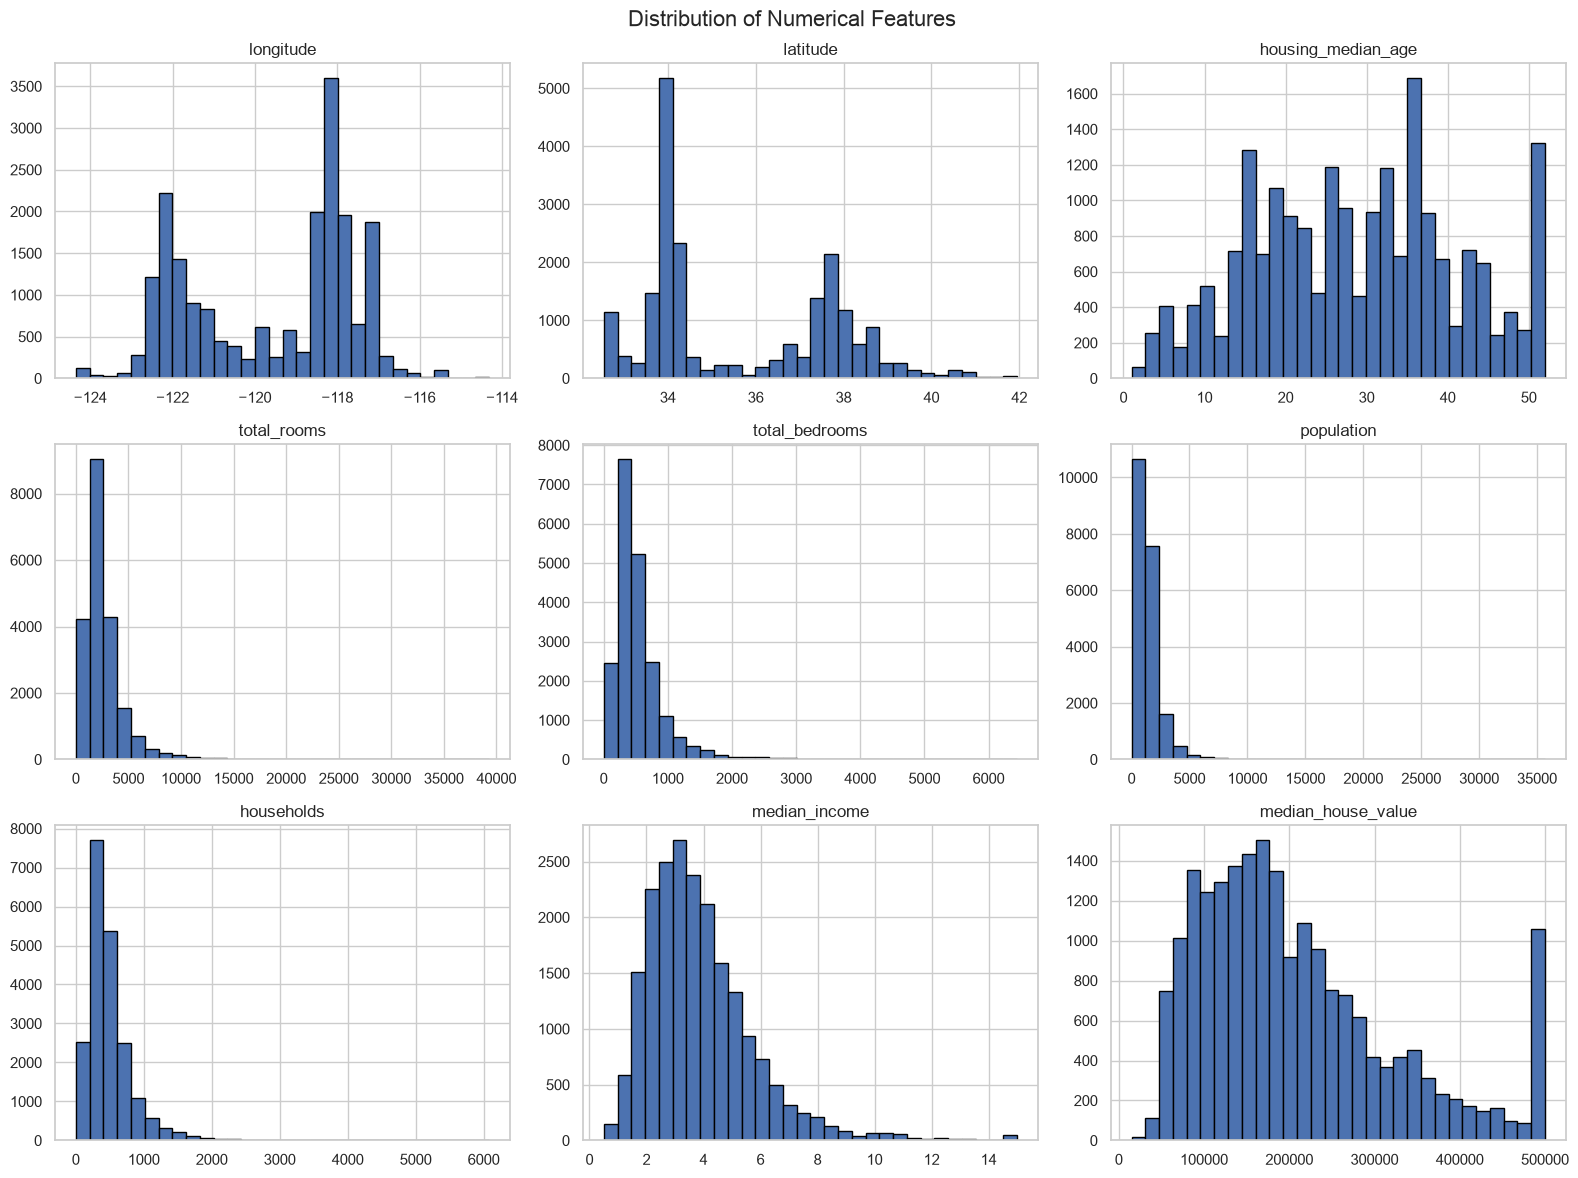

In [7]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns

df[numerical_columns].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)

plt.tight_layout()
plt.show()

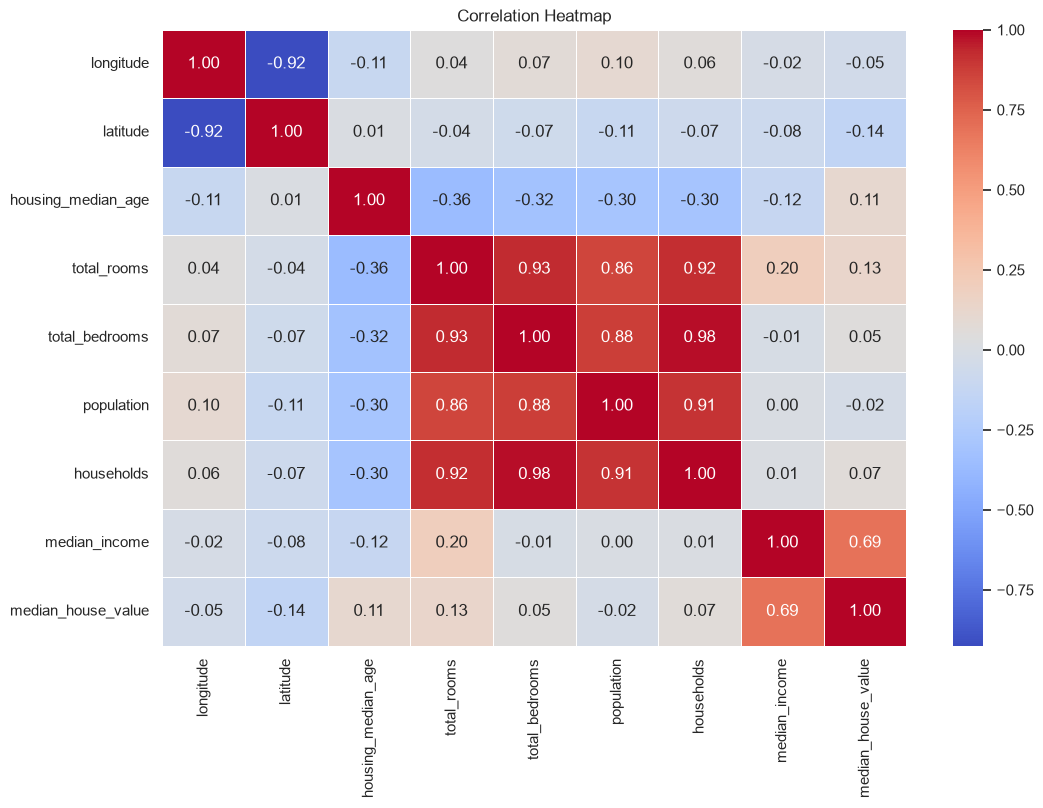

In [14]:
correlation_matrix = df.select_dtypes(
    include=np.number
).corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.show()

In [ ]:
### Correlation Analysis

Key Observations:

1. Median income has the strongest positive correlation
   with median house value (0.69).

2. Longitude and latitude show a strong negative
   correlation (-0.92).

3. Total bedrooms and households have a very high
   positive correlation (0.98).

4. Total rooms and total bedrooms are also highly
   correlated (0.93).

5. Strong correlations among input features indicate
   potential multicollinearity.

Conclusion:

Median income appears to be an important predictor
of housing prices.

Regularization techniques such as Ridge and Lasso
will be evaluated to understand their effectiveness
in handling multicollinearity.

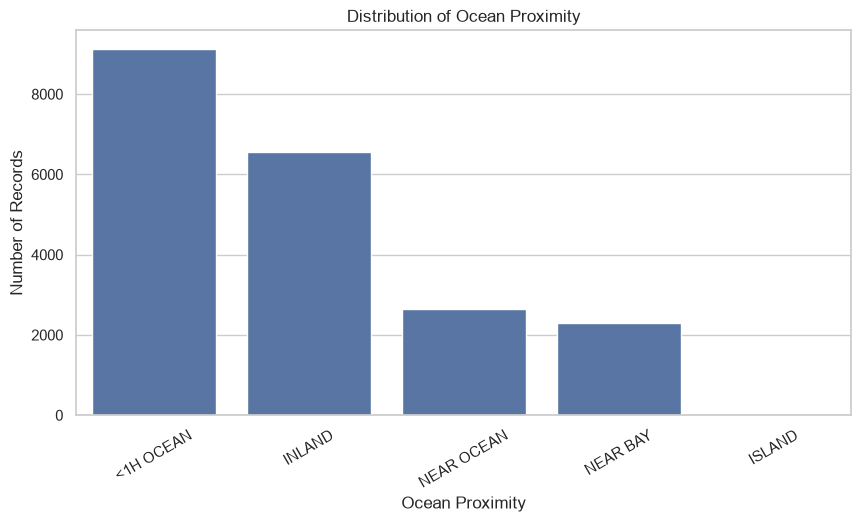

In [9]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="ocean_proximity",
    order=df["ocean_proximity"].value_counts().index
)

plt.title("Distribution of Ocean Proximity")
plt.xlabel("Ocean Proximity")
plt.ylabel("Number of Records")

plt.xticks(rotation=30)

plt.show()

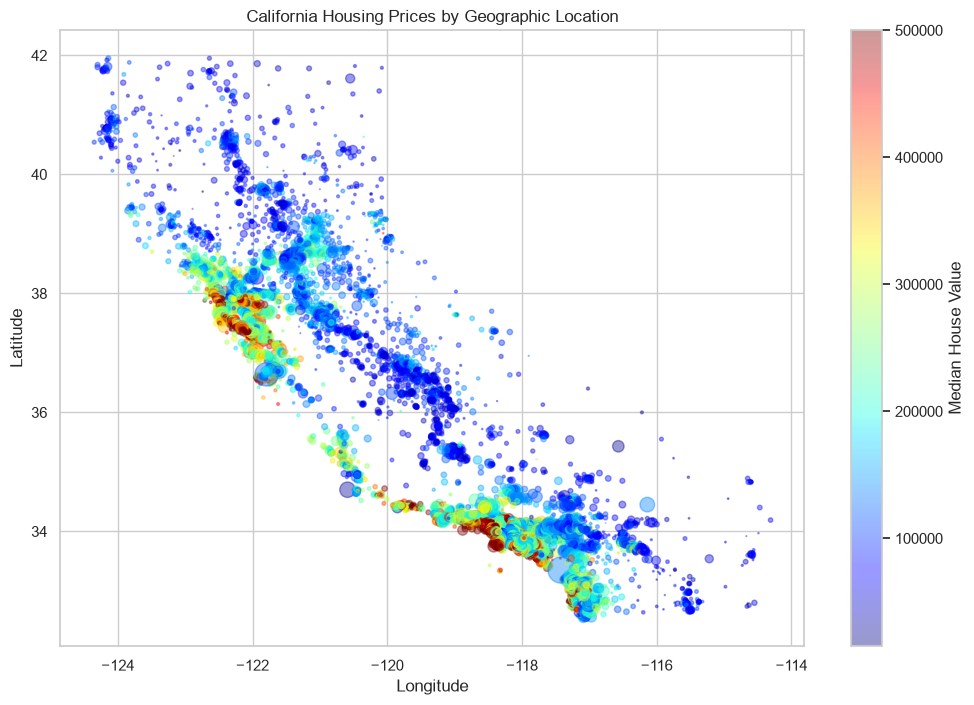

In [13]:
from pathlib import Path

plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    df["longitude"],
    df["latitude"],
    c=df["median_house_value"],
    cmap="jet",
    alpha=0.4,
    s=df["population"] / 100
)

plt.colorbar(
    scatter,
    label="Median House Value"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.title("California Housing Prices by Geographic Location")

# Create the correct directory automatically
figures_dir = Path("../reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

# Save the visualization
plt.savefig(
    figures_dir / "geographical_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
### Geographical Distribution Analysis

Observations:

1. Coastal regions generally show higher median housing values.
2. Inland regions tend to have relatively lower housing prices.
3. Geographic coordinates (longitude and latitude) may be
   useful features for predicting house prices.
4. Population distribution varies across geographical regions.
5. The dataset shows a maximum recorded house value of $500,001,
   suggesting a ceiling effect in the target variable.

Conclusion:

Geographical location appears to be an important factor
associated with housing prices. Therefore, longitude and
latitude will be retained as input features during model
development.

SyntaxError: leading zeros in decimal integer literals are not permitted; use an 0o prefix for octal integers (249775183.py, line 10)

In [16]:
# ==========================================
# SEPARATE FEATURES AND TARGET
# ==========================================

X = df.drop("median_house_value", axis=1)

y = df["median_house_value"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 9)
Target shape: (20640,)


In [17]:
# ==========================================
# TRAIN-TEST SPLIT
# ==========================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (16512, 9)
Testing features: (4128, 9)
Training target: (16512,)
Testing target: (4128,)


In [18]:
# ==========================================
# FEATURE ENGINEERING
# ==========================================

def create_features(data):

    data = data.copy()

    data["rooms_per_household"] = (
        data["total_rooms"] /
        data["households"].replace(0, np.nan)
    )

    data["bedrooms_per_room"] = (
        data["total_bedrooms"] /
        data["total_rooms"].replace(0, np.nan)
    )

    data["population_per_household"] = (
        data["population"] /
        data["households"].replace(0, np.nan)
    )

    return data


# Apply feature engineering separately
X_train = create_features(X_train)
X_test = create_features(X_test)


print("Feature engineering completed!")

print("\nTraining dataset shape:", X_train.shape)
print("Testing dataset shape:", X_test.shape)

print("\nNew features:")
display(
    X_train[
        [
            "rooms_per_household",
            "bedrooms_per_room",
            "population_per_household"
        ]
    ].head()
)

Feature engineering completed!

Training dataset shape: (16512, 12)
Testing dataset shape: (4128, 12)

New features:


,rooms_per_household,bedrooms_per_room,population_per_household
14196,5.017657,0.200576,3.691814
8267,4.473545,0.232703,1.738095
17445,5.645833,0.174486,2.723214
14265,4.002817,0.258269,3.994366
2271,6.268421,0.180940,2.300000


In [19]:
# Identify numerical and categorical columns

numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = ["ocean_proximity"]

print("Numerical features:", numerical_features)
print("\nNumber of numerical features:", len(numerical_features))

print("\nCategorical features:", categorical_features)

Numerical features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household']

Number of numerical features: 11

Categorical features: ['ocean_proximity']


In [20]:
# ==========================================
# DATA PREPROCESSING PIPELINE
# ==========================================

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [21]:
# Fit preprocessing on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using training-fitted transformations
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")

print("\nProcessed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Preprocessing completed successfully!

Processed training shape: (16512, 16)
Processed testing shape: (4128, 16)


In [22]:
# Display transformed feature names

feature_names = preprocessor.get_feature_names_out()

print("Total processed features:", len(feature_names))

print("\nProcessed feature names:")

for feature in feature_names:
    print(feature)

Total processed features: 16

Processed feature names:
num__longitude
num__latitude
num__housing_median_age
num__total_rooms
num__total_bedrooms
num__population
num__households
num__median_income
num__rooms_per_household
num__bedrooms_per_room
num__population_per_household
cat__ocean_proximity_<1H OCEAN
cat__ocean_proximity_INLAND
cat__ocean_proximity_ISLAND
cat__ocean_proximity_NEAR BAY
cat__ocean_proximity_NEAR OCEAN


In [23]:
import scipy.sparse as sp

if sp.issparse(X_train_processed):
    missing_count = np.isnan(X_train_processed.data).sum()
else:
    missing_count = np.isnan(X_train_processed).sum()

print("Missing values after preprocessing:", missing_count)

Missing values after preprocessing: 0


In [24]:
# ==========================================
# IMPORT REGRESSION MODELS
# ==========================================

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import Pipeline

# Create model pipelines

linear_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0))
])

lasso_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Lasso(alpha=1.0, max_iter=10000))
])

print("All three model pipelines created successfully!")

All three model pipelines created successfully!


In [25]:
# ==========================================
# MODEL TRAINING
# ==========================================

models = {
    "Linear Regression": linear_pipeline,
    "Ridge Regression": ridge_pipeline,
    "Lasso Regression": lasso_pipeline
}

for name, model in models.items():

    print(f"Training {name}...")

    model.fit(X_train, y_train)

    print(f"{name} trained successfully!\n")

print("All models trained successfully!")

Training Linear Regression...
Linear Regression trained successfully!

Training Ridge Regression...
Ridge Regression trained successfully!

Training Lasso Regression...
Lasso Regression trained successfully!

All models trained successfully!


In [26]:
# ==========================================
# MODEL PREDICTIONS
# ==========================================

predictions = {}

for name, model in models.items():

    predictions[name] = model.predict(X_test)

    print(f"{name} predictions generated.")

print("\nPrediction process completed!")

Linear Regression predictions generated.
Ridge Regression predictions generated.
Lasso Regression predictions generated.

Prediction process completed!


In [27]:
# ==========================================
# MODEL EVALUATION
# ==========================================

results = []

for name, y_pred in predictions.items():

    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE"
).reset_index(drop=True)

display(results_df.round(4))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,49645.4924,69127.0383,0.6353
1,Lasso Regression,49646.4289,69128.0912,0.6353
2,Ridge Regression,49652.1429,69134.9653,0.6353


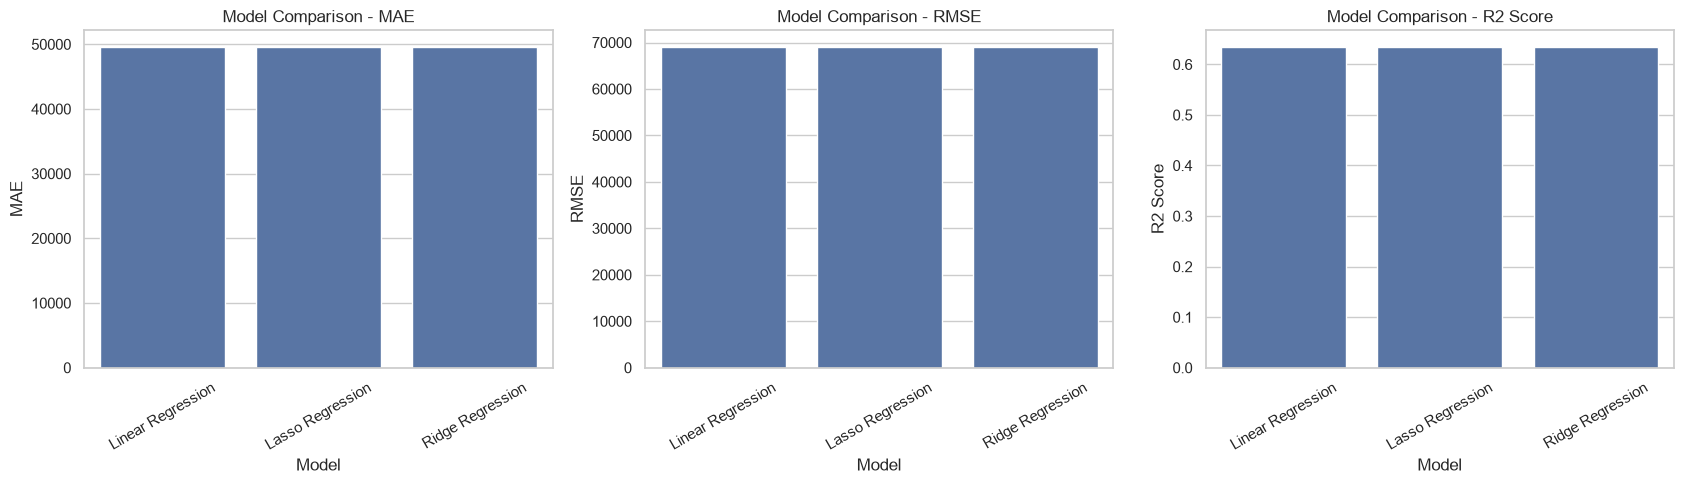

In [28]:
# ==========================================
# MODEL PERFORMANCE COMPARISON
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metrics = ["MAE", "RMSE", "R2 Score"]

for ax, metric in zip(axes, metrics):

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric,
        ax=ax
    )

    ax.set_title(f"Model Comparison - {metric}")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()

figures_dir = Path("../reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [29]:
from sklearn.model_selection import GridSearchCV

In [30]:
# ==========================================
# RIDGE REGRESSION HYPERPARAMETER TUNING
# ==========================================

ridge_params = {
    "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100]
}

ridge_grid = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_params,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

ridge_grid.fit(X_train, y_train)

print("Best Ridge Parameters:", ridge_grid.best_params_)
print("Best Cross-Validation RMSE:", -ridge_grid.best_score_)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best Ridge Parameters: {'model__alpha': 1}
Best Cross-Validation RMSE: 67847.5855222601


In [31]:
# ==========================================
# LASSO REGRESSION HYPERPARAMETER TUNING
# ==========================================

lasso_params = {
    "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100]
}

lasso_grid = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_params,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

lasso_grid.fit(X_train, y_train)

print("Best Lasso Parameters:", lasso_grid.best_params_)
print("Best Cross-Validation RMSE:", -lasso_grid.best_score_)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best Lasso Parameters: {'model__alpha': 1}
Best Cross-Validation RMSE: 67848.71226030539


In [32]:
# ==========================================
# TUNED MODEL EVALUATION
# ==========================================

tuned_models = {
    "Ridge Tuned": ridge_grid.best_estimator_,
    "Lasso Tuned": lasso_grid.best_estimator_
}

tuned_results = []

for name, model in tuned_models.items():

    y_pred = model.predict(X_test)

    tuned_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2 Score": r2_score(y_test, y_pred)
    })

tuned_results_df = pd.DataFrame(tuned_results)

display(tuned_results_df.round(4))

,Model,MAE,RMSE,R2 Score
0,Ridge Tuned,49652.1429,69134.9653,0.6353
1,Lasso Tuned,49646.4289,69128.0912,0.6353


In [33]:
# Combine baseline and tuned results

final_comparison = pd.concat(
    [results_df, tuned_results_df],
    ignore_index=True
)

final_comparison = final_comparison.sort_values(
    by="RMSE"
).reset_index(drop=True)

display(final_comparison.round(4))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,49645.4924,69127.0383,0.6353
1,Lasso Regression,49646.4289,69128.0912,0.6353
2,Lasso Tuned,49646.4289,69128.0912,0.6353
3,Ridge Regression,49652.1429,69134.9653,0.6353
4,Ridge Tuned,49652.1429,69134.9653,0.6353


In [34]:
# ==========================================
# SELECT BEST BASELINE MODEL
# ==========================================

best_model = linear_pipeline

# Generate predictions
y_pred_best = best_model.predict(X_test)

# Calculate residuals
residuals = y_test - y_pred_best

print("Selected Model: Linear Regression")
print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred_best))

Selected Model: Linear Regression
Predictions generated successfully!
Number of predictions: 4128


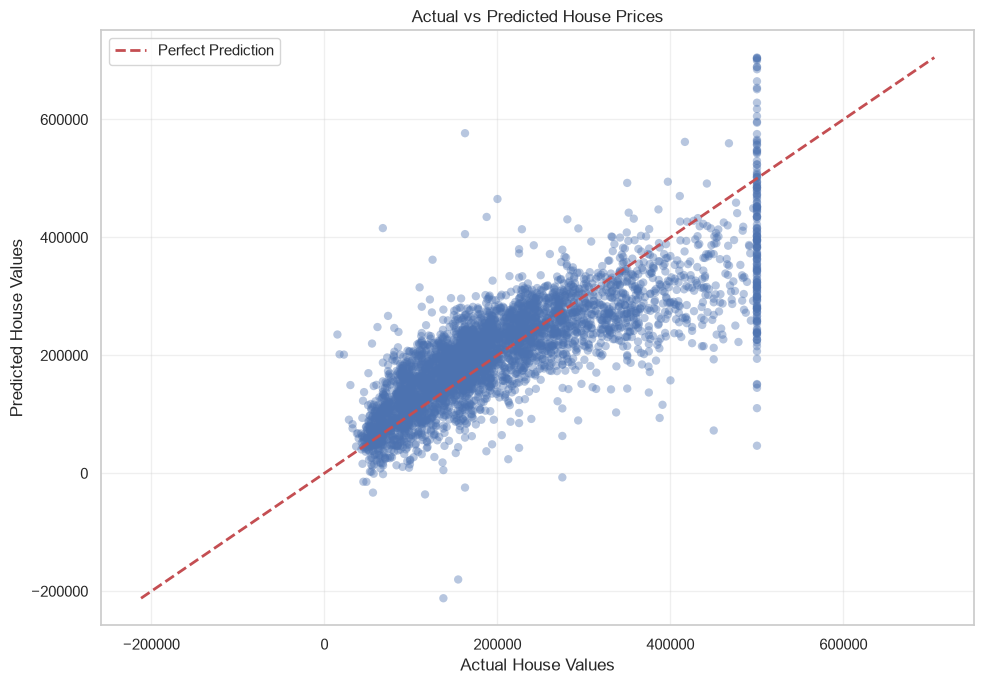

In [35]:
# ==========================================
# ACTUAL VS PREDICTED VALUES
# ==========================================

plt.figure(figsize=(10, 7))

plt.scatter(
    y_test,
    y_pred_best,
    alpha=0.4,
    edgecolors="none"
)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred_best.min())
max_value = max(y_test.max(), y_pred_best.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")

plt.title("Actual vs Predicted House Prices")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

figures_dir = Path("../reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

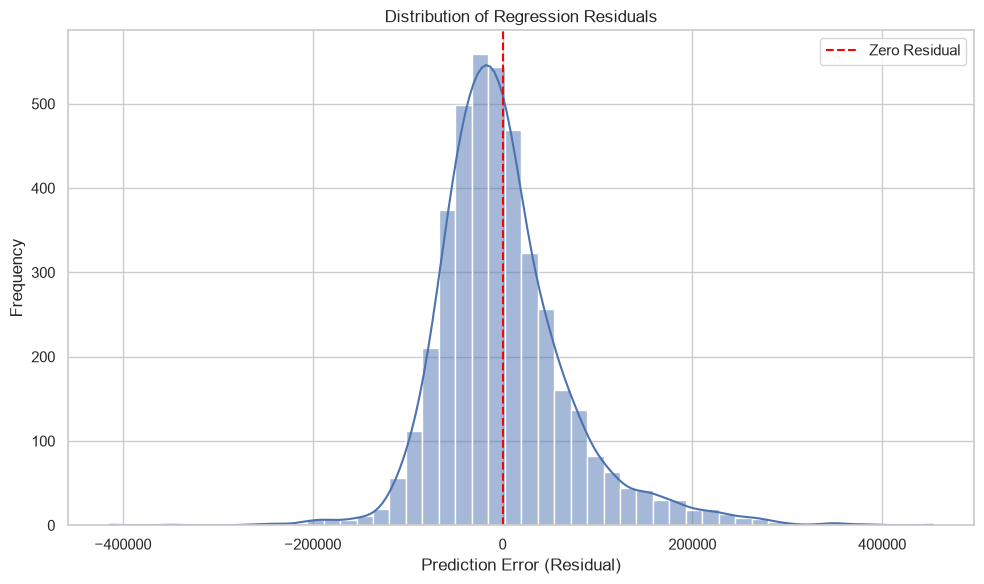

In [36]:
# ==========================================
# RESIDUAL DISTRIBUTION
# ==========================================

plt.figure(figsize=(10, 6))

sns.histplot(
    residuals,
    bins=50,
    kde=True
)

plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    label="Zero Residual"
)

plt.xlabel("Prediction Error (Residual)")
plt.ylabel("Frequency")

plt.title("Distribution of Regression Residuals")

plt.legend()
plt.tight_layout()

plt.savefig(
    figures_dir / "residual_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

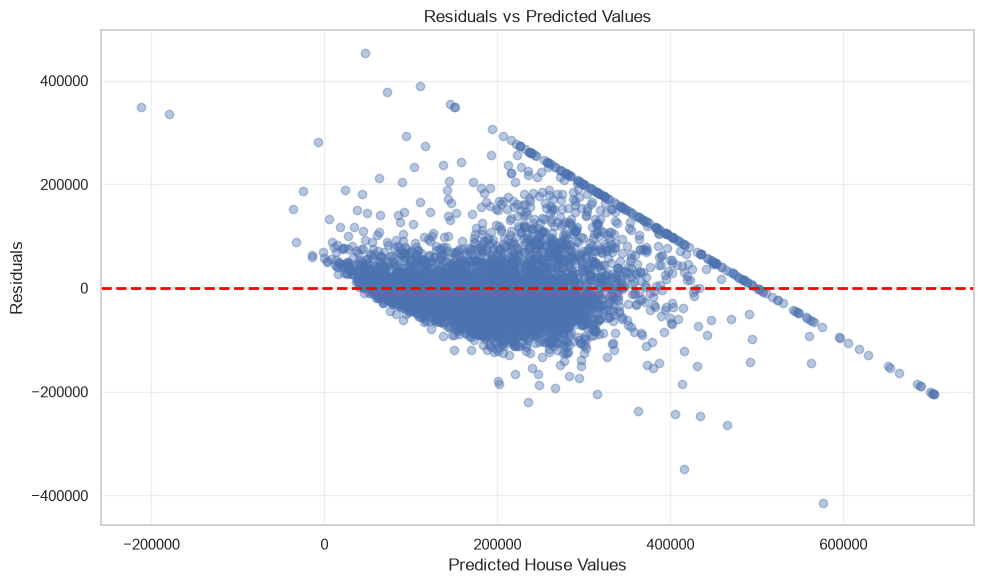

In [37]:
# ==========================================
# RESIDUALS VS PREDICTED VALUES
# ==========================================

plt.figure(figsize=(10, 6))

plt.scatter(
    y_pred_best,
    residuals,
    alpha=0.4
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2
)

plt.xlabel("Predicted House Values")
plt.ylabel("Residuals")

plt.title("Residuals vs Predicted Values")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_dir / "residuals_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
# ==========================================
# RESIDUAL STATISTICS
# ==========================================

print("Residual Analysis Summary")
print("-" * 40)

print("Mean Residual:", round(residuals.mean(), 2))
print("Residual Standard Deviation:", round(residuals.std(), 2))
print("Maximum Residual:", round(residuals.max(), 2))
print("Minimum Residual:", round(residuals.min(), 2))

print("\nBest Model Performance")
print("-" * 40)

print("MAE:", round(mean_absolute_error(y_test, y_pred_best), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred_best)), 2))
print("R2 Score:", round(r2_score(y_test, y_pred_best), 4))

Residual Analysis Summary
----------------------------------------
Mean Residual: 783.76
Residual Standard Deviation: 69130.97
Maximum Residual: 453363.64
Minimum Residual: -414151.57

Best Model Performance
----------------------------------------
MAE: 49645.49
RMSE: 69127.04
R2 Score: 0.6353


In [39]:
# ==========================================
# LINEAR REGRESSION COEFFICIENT ANALYSIS
# ==========================================

# Get feature names after preprocessing
feature_names = best_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get model coefficients
coefficients = best_model.named_steps[
    "model"
].coef_

# Create coefficient dataframe
coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Add absolute coefficient for ranking
coefficient_df["Absolute_Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

# Sort by absolute importance
coefficient_df = coefficient_df.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

# Display top 15 features
display(
    coefficient_df[
        ["Feature", "Coefficient"]
    ].head(15).round(4)
)

,Feature,Coefficient
13,cat__ocean_proximity_ISLAND,112060.2445
7,num__median_income,78904.4394
1,num__latitude,-56638.2312
0,num__longitude,-56276.0589
12,cat__ocean_proximity_INLAND,-53617.8404
5,num__population,-46320.2855
6,num__households,40233.7248
14,cat__ocean_proximity_NEAR BAY,-24109.1851
11,cat__ocean_proximity_<1H OCEAN,-18666.4786
9,num__bedrooms_per_room,16809.1046


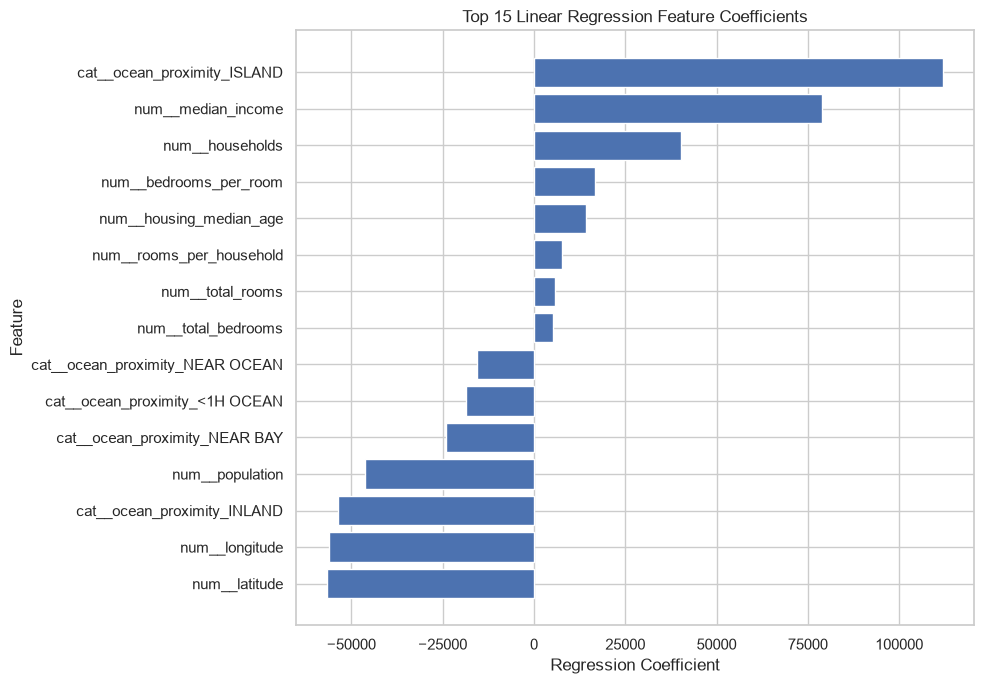

In [40]:
# ==========================================
# TOP FEATURE COEFFICIENTS
# ==========================================

top_features = coefficient_df.head(15).sort_values(
    by="Coefficient"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.xlabel("Regression Coefficient")
plt.ylabel("Feature")

plt.title(
    "Top 15 Linear Regression Feature Coefficients"
)

plt.tight_layout()

plt.savefig(
    figures_dir / "feature_coefficients.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [41]:
# ==========================================
# SAVE FINAL MODEL
# ==========================================

import joblib
from pathlib import Path

models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

model_path = models_dir / "california_housing_linear_regression.joblib"

joblib.dump(best_model, model_path)

print("Model saved successfully!")
print("Location:", model_path.resolve())

Model saved successfully!
Location: /Users/anirudhgarg/Desktop/Datheon/Datheon-ML-Internship/Task-2-Housing-Price-Prediction/models/california_housing_linear_regression.joblib


In [42]:
# ==========================================
# VERIFY SAVED MODEL
# ==========================================

loaded_model = joblib.load(model_path)

sample_predictions = loaded_model.predict(
    X_test.head(5)
)

print("Model loaded successfully!")
print("\nSample predictions:")

for i, prediction in enumerate(sample_predictions, 1):
    print(f"Sample {i}: ${prediction:,.2f}")

Model loaded successfully!

Sample predictions:
Sample 1: $36,496.16
Sample 2: $137,597.77
Sample 3: $293,482.55
Sample 4: $281,736.02
Sample 5: $263,392.55
